## Overview and methodology

This notebook performs **repeated stratified cross-validation** exclusively on the development partition (`train` and `validation` splits) to evaluate and compare candidate model configurations without touching the final temporal test set.

### What is evaluated?
- **Model Configurations:** Tests multiple model types (e.g., Logistic Regression vs. XGBoost) across predefined feature sets.
- **Robust Resampling:** Uses `RepeatedStratifiedKFold` (default: 5 splits, 3 repeats = 15 folds) to ensure stable out-of-sample estimates.
- **Leakage Prevention:** Preprocessing, scaling, and model fitting are re-fitted inside every fold independently.
- **Summarisation:** Fold-level metrics (AUROC, AUPRC, Brier score, sensitivity, specificity, PPV, NPV) are aggregated using medians and interquartile ranges (IQRs) to handle skewness robustly.

In [6]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [1]:
from pathlib import Path
import yaml
from IPython.display import display

from icare_risk.data.audit import load_admission_file
from icare_risk.evaluation.cross_validation import cross_validate_models

# Load analysis configuration
CONFIG_PATH = Path('../../src/icare_risk/config/icare/analysis.yaml')
with CONFIG_PATH.open() as f:
    config = yaml.safe_load(f)

# Load processed dataset and filter strictly to development split
df = load_admission_file(config['outputs']['processed_dataset'])
development = df.loc[df['split'].isin(['train', 'validation'])].copy()

target = config['columns']['target']
target_mapping = config.get('target_mapping', config.get('analysis', {}).get('target_mapping', {}))

print(f'Development admissions: {len(development):,}')

Development admissions: 7,517


In [2]:
cv_cfg = config.get('cross_validation', {})

# Run repeated stratified cross-validation across all configured models and feature sets
fold_results, cv_summary = cross_validate_models(
    development,
    config['models'],
    config['feature_sets'],
    target=target,
    target_mapping=target_mapping,
    exclude_columns=[target, 'split'],
    n_splits=cv_cfg.get('n_splits', 5),
    n_repeats=cv_cfg.get('n_repeats', 3),
    threshold=config.get('analysis').get('evaluation_threshold'),
    random_state=cv_cfg.get('random_state', 42),
)

# Display summary sorted by metric and median performance
display(cv_summary.sort_values(['metric', 'median'], ascending=[True, False]).reset_index(drop=True))
display(fold_results.head())

,model,n_features,metric,n_folds,median,q1,q3,iqr,mean,sd
0,xgb_clinical_baseline,16,auprc,15,0.213524,0.207243,0.218506,0.011263,0.211948,0.009300
1,lr_clinical_baseline,16,auprc,15,0.208810,0.202259,0.218394,0.016135,0.211079,0.010434
2,lr_kim_components,5,auprc,15,0.200586,0.197994,0.201413,0.003419,0.199678,0.002214
3,xgb_kim_components,5,auprc,15,0.200586,0.197994,0.201413,0.003419,0.199696,0.002227
4,lr_all_score_values,6,auprc,15,0.198238,0.190296,0.200952,0.010656,0.195999,0.006518
5,xgb_all_score_values,6,auprc,15,0.184106,0.180067,0.189973,0.009907,0.184337,0.007018
6,lr_clinical_baseline,16,auroc,15,0.519769,0.510502,0.527940,0.017438,0.517868,0.014393
7,xgb_clinical_baseline,16,auroc,15,0.517625,0.500811,0.520199,0.019388,0.512833,0.013089
8,lr_kim_components,5,auroc,15,0.508681,0.501399,0.510817,0.009418,0.506185,0.006754
9,xgb_kim_components,5,auroc,15,0.508681,0.501399,0.510817,0.009418,0.506286,0.006833


,model,n_features,repeat,fold,n_train,n_validation,model_type,n,n_events,event_rate,...,tn,fp,fn,sensitivity,specificity,ppv,npv,accuracy,balanced_accuracy,f1
0,lr_kim_components,5,1,1,6013,1504,logistic_regression,1504,297,0.197473,...,125,1082,25,0.915825,0.103563,0.200886,0.833333,0.263963,0.509694,0.329497
1,lr_kim_components,5,1,2,6013,1504,logistic_regression,1504,297,0.197473,...,113,1094,28,0.905724,0.093621,0.197359,0.801418,0.253989,0.499672,0.324096
2,lr_kim_components,5,1,3,6014,1503,logistic_regression,1503,297,0.197605,...,147,1059,31,0.895623,0.121891,0.200755,0.825843,0.274784,0.508757,0.327990
3,lr_kim_components,5,1,4,6014,1503,logistic_regression,1503,297,0.197605,...,141,1065,33,0.888889,0.116915,0.198646,0.810345,0.269461,0.502902,0.324723
4,lr_kim_components,5,1,5,6014,1503,logistic_regression,1503,297,0.197605,...,138,1068,27,0.909091,0.114428,0.201794,0.836364,0.271457,0.511759,0.330275


In [3]:
output_directory = Path(config['outputs']['metrics_directory'])
output_directory.mkdir(parents=True, exist_ok=True)
fold_results.to_csv(output_directory / 'cross_validation_folds.csv', index=False)
cv_summary.to_csv(output_directory / 'cross_validation_summary.csv', index=False)
print(f'Saved cross-validation results to {output_directory}')

Saved cross-validation results to results/metrics


## Advanced Visualisation: Empirical Distribution Across Cross-Validation Folds

Instead of relying solely on summary point estimates (like medians or means), this visualization loads the saved **fold-level results (`cross_validation_folds.csv`)** and constructs a **Faceted Box-and-Strip Plot**.

### Why this is superior for clinical machine learning:
1. **Full Distribution Visibility:** Combining box plots with overlaid jittered points (strip plots) exposes the true empirical distribution across all 15 folds (5 splits × 3 repeats). You can instantly see outlier folds, variance, and stability.
2. **Side-by-Side Model Comparison:** It cleanly facets key metrics (`auroc`, `auprc`, and `brier_score`) into separate panels, allowing you to evaluate discrimination and calibration trade-offs simultaneously.
3. **Publication-Ready Rigor:** This style of plot is standard in top-tier medical and machine learning journals because it prevents hiding model instability behind single aggregate numbers.

Successfully loaded fold results from: results/metrics/cross_validation_folds.csv
Total fold records loaded: 90


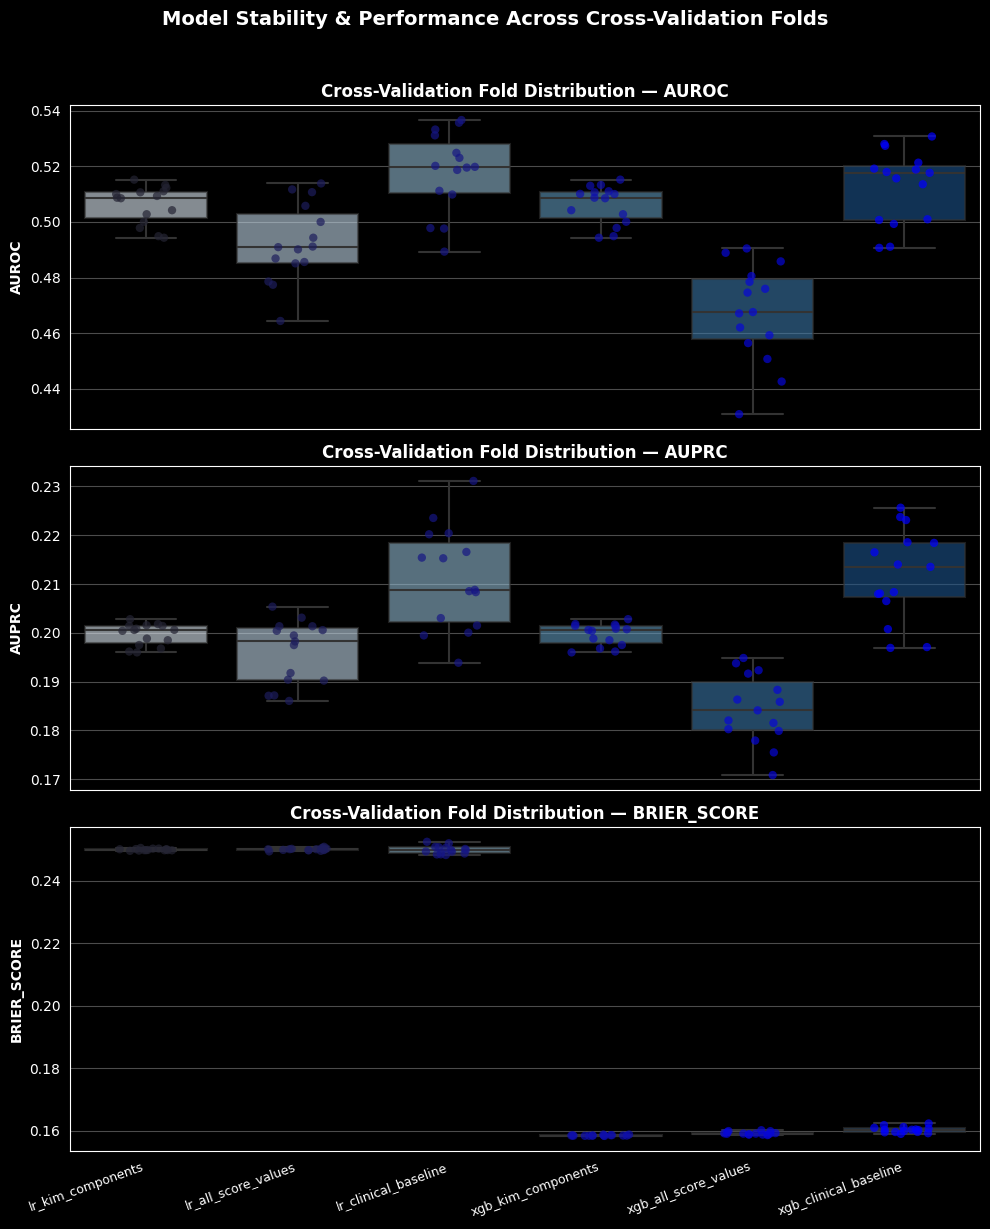

In [5]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

# 1. Load configuration to locate the metrics directory
CONFIG_PATH = Path('../../src/icare_risk/config/icare/analysis.yaml')
with CONFIG_PATH.open() as f:
    config = yaml.safe_load(f)

metrics_directory = Path(config.get('outputs', {}).get('metrics_directory', 'results/metrics'))
folds_path = metrics_directory / 'cross_validation_folds.csv'

# 2. Load the saved fold-level cross-validation results from disk
if not folds_path.exists():
    raise FileNotFoundError(f"Could not find saved fold results at {folds_path}. Please run the cross-validation cell first!")

fold_results = pd.read_csv(folds_path)
print(f"Successfully loaded fold results from: {folds_path}")
print(f"Total fold records loaded: {len(fold_results):,}")

# 3. Prepare data for multi-panel distribution plotting
key_metrics = ['auroc', 'auprc', 'brier_score']
available_metrics = [m for m in key_metrics if m in fold_results.columns]

# Reshape data using melt to make it tidy for seaborn faceted plotting
plot_df = fold_results.melt(
    id_vars=['model', 'n_features', 'repeat', 'fold'],
    value_vars=available_metrics,
    var_name='metric',
    value_name='score'
)

# 4. Build the advanced publication-grade faceted Box & Strip plot
fig, axes = plt.subplots(len(available_metrics), 1, figsize=(10, 4 * len(available_metrics)), sharex=True)
if len(available_metrics) == 1:
    axes = [axes]

for idx, metric in enumerate(available_metrics):
    ax = axes[idx]
    subset = plot_df[plot_df['metric'] == metric]

    # Draw background box plot to show IQR and median (fixed by adding hue and legend=False)
    sns.boxplot(
        data=subset,
        x='model',
        y='score',
        hue='model',        # <-- Fix: assign hue
        ax=ax,
        palette='Blues',
        boxprops=dict(alpha=0.6),
        fliersize=0,
        linewidth=1.5,
        legend=False        # <-- Fix: disable legend
    )

    # Overlay jittered strip plot to show individual fold outcomes (fixed by adding hue and legend=False)
    sns.stripplot(
        data=subset,
        x='model',
        y='score',
        hue='model',        # <-- Fix: assign hue
        ax=ax,
        palette='dark:blue',# <-- Use palette or color (dark:blue works cleanly with hue in newer seaborn)
        alpha=0.7,
        jitter=0.2,
        size=6,
        legend=False        # <-- Fix: disable legend
    )

    ax.set_title(f'Cross-Validation Fold Distribution — {metric.upper()}', fontsize=12, fontweight='bold')
    ax.set_ylabel(metric.upper(), fontsize=10, fontweight='semibold')
    ax.set_xlabel('')
    ax.grid(True, axis='y', alpha=0.3)
    plt.setp(ax.get_xticklabels(), rotation=20, ha='right', fontsize=9)

plt.suptitle('Model Stability & Performance Across Cross-Validation Folds', y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

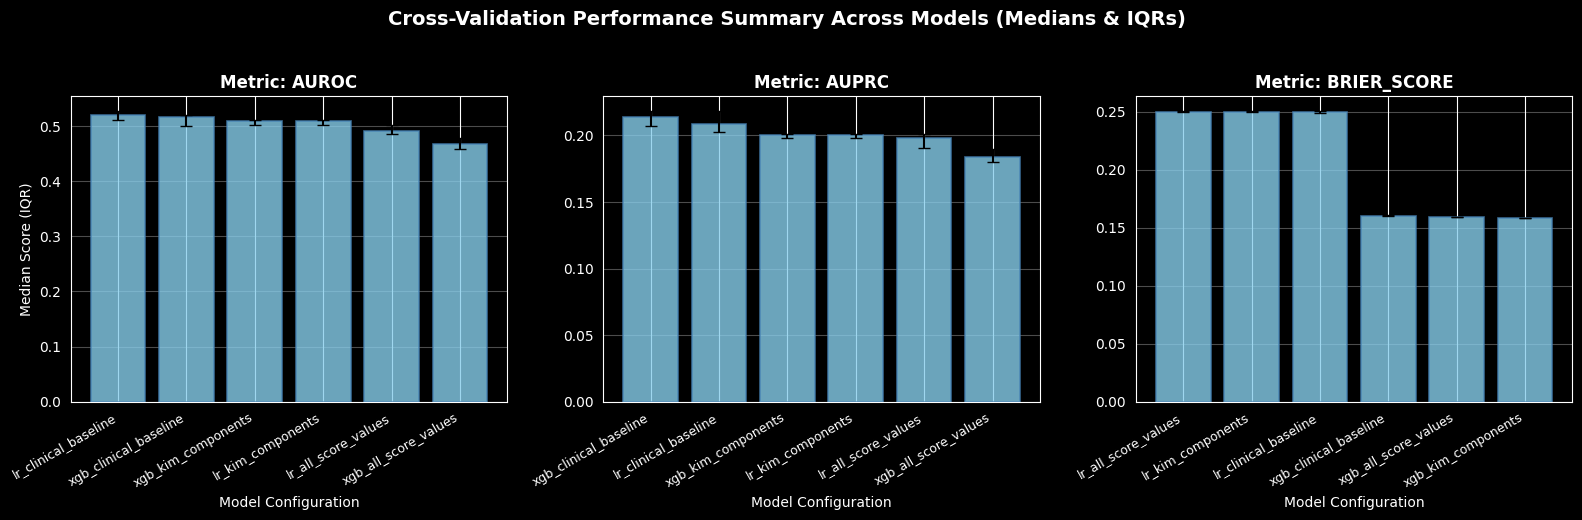

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Filter summary for key clinical metrics
metrics_to_plot = ['auroc', 'auprc', 'brier_score']
plot_data = cv_summary[cv_summary['metric'].isin(metrics_to_plot)].copy()

# Calculate error bar heights (distance from median to Q1 and Q3)
plot_data['yerr_lower'] = plot_data['median'] - plot_data['q1']
plot_data['yerr_upper'] = plot_data['q3'] - plot_data['median']

# Create a multi-panel figure using standard matplotlib/seaborn subplots for precise error bar control
fig, axes = plt.subplots(1, len(metrics_to_plot), figsize=(16, 5), sharey=False)

for idx, metric in enumerate(metrics_to_plot):
    ax = axes[idx]
    subset = plot_data[plot_data['metric'] == metric].sort_values('median', ascending=False)

    # Plot bars
    bars = ax.bar(
        subset['model'],
        subset['median'],
        yerr=[subset['yerr_lower'], subset['yerr_upper']],
        capsize=4,
        color='skyblue',
        edgecolor='steelblue',
        alpha=0.8,
        linewidth=1.2
    )

    ax.set_title(f'Metric: {metric.upper()}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Median Score (IQR)' if idx == 0 else '', fontsize=10)
    ax.set_xlabel('Model Configuration', fontsize=10)
    ax.grid(True, axis='y', alpha=0.3)

    # Rotate x tick labels for readability
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right', fontsize=9)

plt.suptitle('Cross-Validation Performance Summary Across Models (Medians & IQRs)', y=1.03, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()